# 07b · Player-level view: do Combine drills predict a DL's average get-off?
**DS 5110 Big Data Systems — Final Project: Trench Play (OL and DL)**

**Team contribution.** The question and the first scatter (10-yard split against average get-off) are **Isaac Marr's** (EDA). The correlations, the median imputation and the Spark ML linear regression are **Jarmarr Washington's**. This notebook keeps their steps as they wrote them and then adds what the rest of the project needs:
* the **tracking traits** from notebook 03 next to the stopwatch drills (does tracking add anything at the player level?);
* **repeated cross-validation** instead of one 43 / 12 split, so the R² comes with an uncertainty band;
* an **out-of-time test** on the 2025 draft class, as in notebooks 05–07;
* a **reconciliation** with the snap-level models of notebook 07, which found much smaller effects.

**Why look at players, not snaps.** Notebooks 05–07 predict every snap. Averaging a player's snaps removes snap-to-snap noise (the down, the blocker, the stunt), so a player-level model asks a cleaner question: *do players who test faster get off the ball faster on average?*

**Population (as in the original analysis).** DL rookies, NFL regular + post season, snaps lined up on the edge or the interior with a recorded get-off; players with 100+ such snaps and a recorded 10-yard split.

**Inputs:** `processed/line_player_play.parquet`, `line_players.parquet` (stopwatch drills), `trait_indices.parquet` (tracking traits); `outputs/tables/07_*.csv` (optional, for the reconciliation).
**Outputs:** `outputs/tables/07b_*.csv`, `outputs/figures/07b_*.png`.

In [1]:
import sys, os
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))

import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from pyspark.sql import functions as F
from pyspark.sql.window import Window
from pyspark.ml import Pipeline
from pyspark.ml.feature import Imputer, VectorAssembler, StandardScaler
from pyspark.ml.regression import LinearRegression
from pyspark.ml.evaluation import RegressionEvaluator
import config as C

spark = C.get_spark("07b_player_level")
plt.rcParams.update({"figure.dpi": 120, "axes.spines.top": False, "axes.spines.right": False, "font.size": 10})
BLUE, ORANGE, AQUA, GREY = "#2a6fdb", "#e07b39", "#00b894", "#8a8a8a"
CV_REPEATS = int(os.environ.get("PLAYER_CV_REPEATS", "20"))
STOPWATCH = ["ten_yd_split", "forty", "three_cone", "short_shuttle", "vertical", "broad_jump"]
TRACKING = ["trk_first_step", "trk_lateral", "trk_burst"]
LABELS = {"ten_yd_split": "10-yard split (s)", "forty": "40-yard dash (s)", "three_cone": "3-cone (s)", "short_shuttle": "short shuttle (s)",
          "vertical": "vertical jump (in)", "broad_jump": "broad jump (in)", "trk_first_step": "tracking: first step (index)",
          "trk_lateral": "tracking: lateral agility (index)", "trk_burst": "tracking: burst (index)", "edge_share": "share of edge snaps"}

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).


/apps/software/standard/core/spark/4.2.0/python/pyspark/testing/utils.py:127: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


26/11/26 22:16:31 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


## 1. One row per DL: average get-off, rush snaps, share of edge snaps (Spark)

In [2]:
plays = spark.read.parquet(C.p("line_player_play.parquet"))
players = spark.read.parquet(C.p("line_players.parquet"))
traits = spark.read.parquet(C.p("trait_indices.parquet")).select("nfl_id", *TRACKING)
rush = plays.filter((F.col("line_group") == "DL") & F.col("season_type").isin("REG", "POST") & F.col("player_get_off").isNotNull()
                    & F.col("lined_up_position").isin("EDGE", "INTERIOR_LINE"))
per_player = (rush.groupBy("nfl_id").agg(F.count("*").alias("rush_snaps"), F.avg("player_get_off").alias("mean_get_off"),
                                         F.avg((F.col("lined_up_position") == "EDGE").cast("double")).alias("edge_share"))
                  .join(players.select("nfl_id", "display_name", "draft_year", *STOPWATCH), "nfl_id")
                  .join(traits, "nfl_id", "left"))
dl = per_player.filter((F.col("rush_snaps") >= 100) & F.col("ten_yd_split").isNotNull()).cache()
n_dl = dl.count()
classes = {r.draft_year: r["count"] for r in dl.groupBy("draft_year").count().orderBy("draft_year").collect()}
print(f"{n_dl} DL with 100+ rush snaps and a 10-yard split (draft classes: {classes})")
C.describe(dl, ["rush_snaps", "mean_get_off", "edge_share"] + STOPWATCH + TRACKING).drop("min").toPandas().round(3)

55 DL with 100+ rush snaps and a 10-yard split (draft classes: {2023: 22, 2024: 22, 2025: 11})


/apps/software/standard/core/spark/4.2.0/python/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


,column,count,mean,std,median,max,missing_pct
0,rush_snaps,55,478.327,422.196,285.000,1802.000,0.000
1,mean_get_off,55,1.035,0.096,1.034,1.206,0.000
2,edge_share,55,0.501,0.428,0.286,1.000,0.000
3,ten_yd_split,55,1.687,0.077,1.670,1.880,0.000
4,forty,55,4.829,0.246,4.810,5.410,0.000
5,three_cone,24,7.432,0.261,7.385,8.010,56.364
6,short_shuttle,23,4.552,0.210,4.540,5.030,58.182
7,vertical,53,32.443,3.577,32.500,38.000,3.636
8,broad_jump,51,116.176,8.037,116.000,132.000,7.273
9,trk_first_step,55,0.039,0.486,0.113,0.895,0.000


## 2. Correlations with average get-off (Jarmarr's table, plus the tracking traits)
Get-off is a time, so a **positive** r for a timed drill (10-yard split, 40, 3-cone, shuttle) and a **negative** r for a jump or a tracking index (higher = better) both mean "better tester, faster get-off". The 95% interval uses the Fisher z transform. All computed in Spark (`config.pearson`, `config.spearman`); the least-squares line for each scatter is fitted in Spark too.

In [3]:
FEATS = [("stopwatch", c) for c in STOPWATCH] + [("tracking", c) for c in TRACKING] + [("context", "edge_share")]
parts = []
for kind, c in FEATS:
    ok = F.col(c).isNotNull()
    line = dl.agg((F.covar_samp(F.when(ok, F.col(c)), F.when(ok, F.col("mean_get_off"))) / F.var_samp(F.when(ok, F.col(c)))).alias("slope"),
                  F.avg(F.when(ok, F.col(c))).alias("xmu"), F.avg(F.when(ok, F.col("mean_get_off"))).alias("ymu"))
    parts.append(C.pearson(dl, c, "mean_get_off").crossJoin(C.spearman(dl, c, "mean_get_off").select(F.col("spearman").alias("spearman_rho")))
                  .crossJoin(line).select(F.lit(c).alias("feature"), F.lit(LABELS[c]).alias("label"), F.lit(kind).alias("kind"), "n",
                                          "pearson_r", "ci_lo", "ci_hi", "spearman_rho", "slope",
                                          (F.col("ymu") - F.col("slope") * F.col("xmu")).alias("intercept")))
corr_s = parts[0]
for p_ in parts[1:]:
    corr_s = corr_s.unionByName(p_)
corr = corr_s.toPandas()
corr.to_csv(C.TABLE_DIR / "07b_correlations.csv", index=False)
corr.round(3)

/apps/software/standard/core/spark/4.2.0/python/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


,feature,label,kind,n,pearson_r,ci_lo,ci_hi,spearman_rho,slope,intercept
0,ten_yd_split,10-yard split (s),stopwatch,55,0.694,0.526,0.810,0.677,0.859,-0.413
1,forty,40-yard dash (s),stopwatch,55,0.698,0.531,0.813,0.710,0.271,-0.275
2,three_cone,3-cone (s),stopwatch,24,0.605,0.267,0.811,0.563,0.228,-0.648
3,short_shuttle,short shuttle (s),stopwatch,23,0.532,0.154,0.775,0.483,0.261,-0.146
4,vertical,vertical jump (in),stopwatch,53,-0.600,-0.749,-0.393,-0.593,-0.016,1.547
5,broad_jump,broad jump (in),stopwatch,51,-0.690,-0.811,-0.512,-0.663,-0.008,1.975
6,trk_first_step,tracking: first step (index),tracking,55,-0.120,-0.373,0.150,-0.142,-0.024,1.036
7,trk_lateral,tracking: lateral agility (index),tracking,52,-0.354,-0.571,-0.089,-0.272,-0.055,1.034
8,trk_burst,tracking: burst (index),tracking,55,-0.341,-0.556,-0.084,-0.346,-0.057,1.034
9,edge_share,share of edge snaps,context,55,-0.613,-0.755,-0.415,-0.655,-0.137,1.104


/apps/software/standard/core/spark/4.2.0/python/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


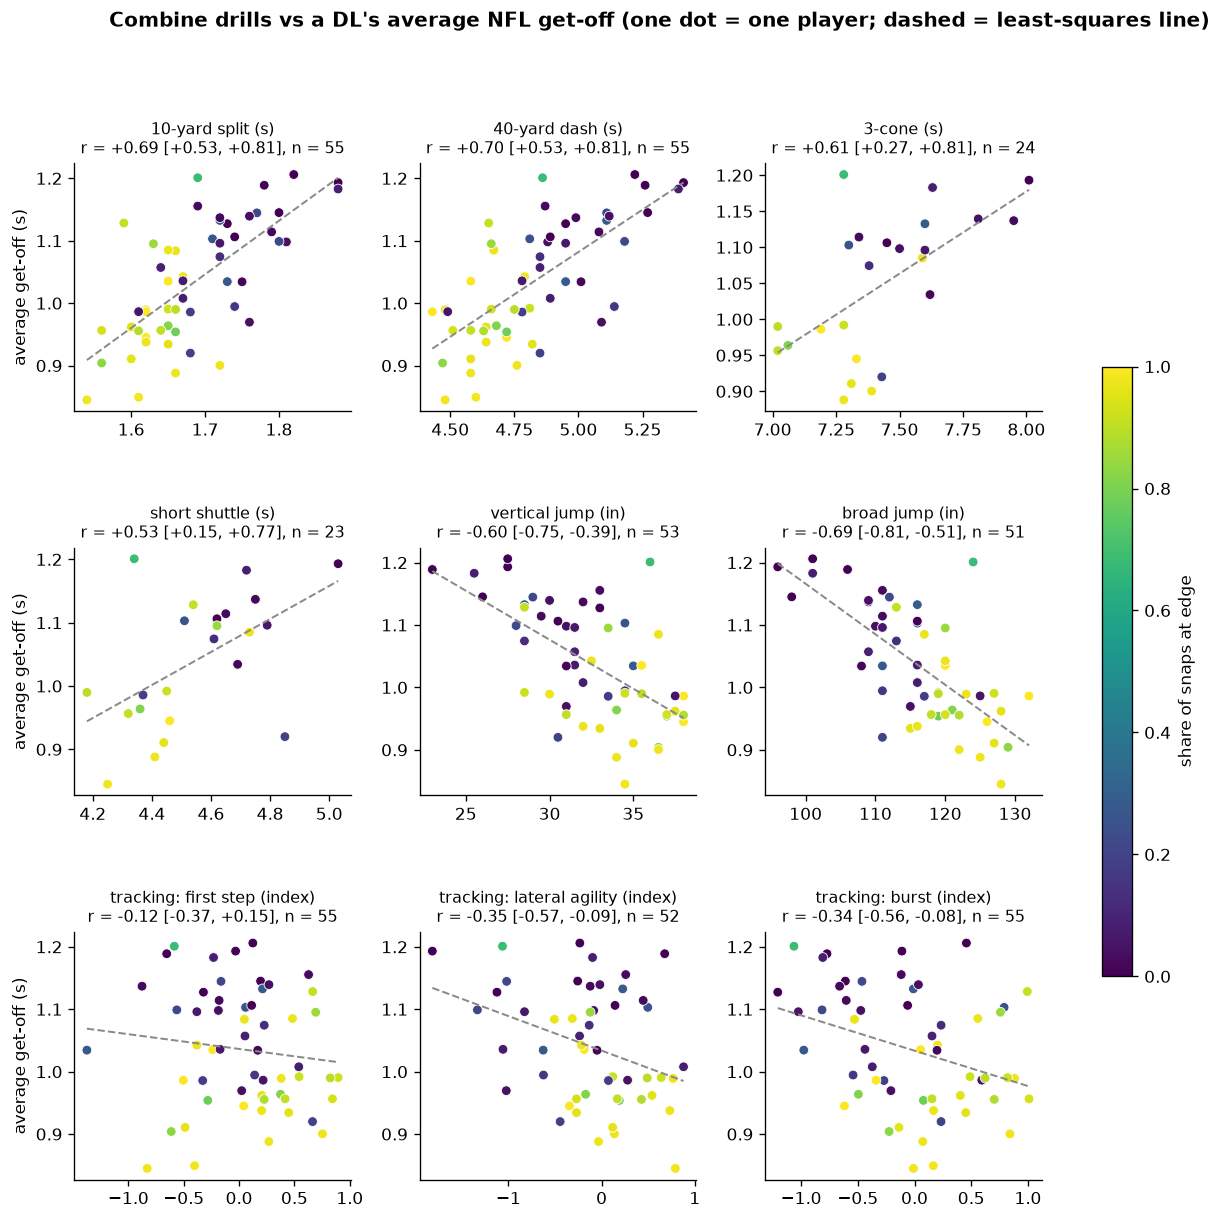

In [4]:
pts = dl.select("mean_get_off", "edge_share", *STOPWATCH, *TRACKING).toPandas()      # 55 points: plotted, not computed on
fig, axes = plt.subplots(3, 3, figsize=(13, 11))
for ax, name in zip(axes.flat, STOPWATCH + TRACKING):
    d = pts[[name, "mean_get_off", "edge_share"]].dropna()
    sc = ax.scatter(d[name], d.mean_get_off, c=d.edge_share, cmap="viridis", vmin=0, vmax=1, s=34, edgecolors="white", linewidths=.5)
    rr = corr.set_index("feature").loc[name]
    xs = np.array([d[name].min(), d[name].max()])
    ax.plot(xs, rr.intercept + rr.slope * xs, color=GREY, lw=1.2, ls="--")
    ax.set_title(f"{LABELS[name]}\nr = {rr.pearson_r:+.2f} [{rr.ci_lo:+.2f}, {rr.ci_hi:+.2f}], n = {int(rr.n)}", fontsize=9.5)
    ax.set_ylabel("average get-off (s)" if ax in axes[:, 0] else "")
fig.subplots_adjust(hspace=.55, wspace=.25)
fig.colorbar(sc, ax=axes, shrink=.6, label="share of snaps at edge")
fig.suptitle("Combine drills vs a DL's average NFL get-off (one dot = one player; dashed = least-squares line)", fontweight="bold", y=0.995)
fig.savefig(C.FIG_DIR / "07b_drills_vs_mean_getoff.png", bbox_inches="tight"); plt.show()

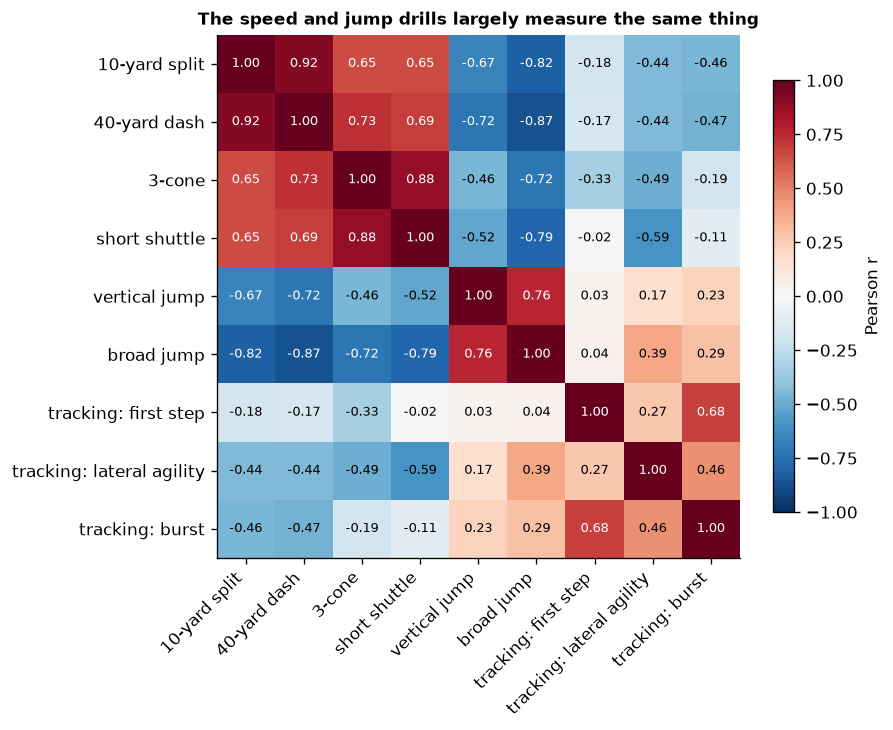

In [5]:
# how much the drills overlap with each other (Jarmarr's inter-correlation table), pairwise in Spark
cols9 = STOPWATCH + TRACKING
row = dl.agg(*[F.corr(a, b).alias(f"{a}__{b}") for i, a in enumerate(cols9) for b in cols9[i + 1:]]).first().asDict()
inter = pd.DataFrame(np.eye(len(cols9)), index=cols9, columns=cols9)
for key_, v in row.items():
    a, b = key_.split("__"); inter.loc[a, b] = inter.loc[b, a] = v
inter = inter.round(2)
inter.to_csv(C.TABLE_DIR / "07b_drill_intercorrelations.csv")
fig, ax = plt.subplots(figsize=(7.5, 6.2))
im = ax.imshow(inter.values, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(inter)), [LABELS[c].split(" (")[0] for c in inter.columns], rotation=45, ha="right")
ax.set_yticks(range(len(inter)), [LABELS[c].split(" (")[0] for c in inter.index])
for i in range(len(inter)):
    for j in range(len(inter)):
        ax.text(j, i, f"{inter.values[i, j]:.2f}", ha="center", va="center", fontsize=7.5,
                color="white" if abs(inter.values[i, j]) > .6 else "black")
fig.colorbar(im, ax=ax, shrink=.8, label="Pearson r")
ax.set_title("The speed and jump drills largely measure the same thing", fontweight="bold", fontsize=10)
fig.tight_layout(); fig.savefig(C.FIG_DIR / "07b_drill_intercorrelations.png", bbox_inches="tight"); plt.show()

## 3. Jarmarr's model, as written
80 / 20 random split of players (seed 42), a mean baseline, median imputation of the drills many players skipped (fitted on the training players only), and a Spark ML linear regression on the six stopwatch drills plus the share of edge snaps.

In [6]:
MISSING = ["three_cone", "short_shuttle", "vertical", "broad_jump"]
JW_FEATURES = ["ten_yd_split", "forty"] + [f"{c}_imputed" for c in MISSING] + ["edge_share"]
dl_spark = dl.select("nfl_id", "draft_year", *[F.col(c).cast("double") for c in ["mean_get_off", "edge_share"] + STOPWATCH + TRACKING])
train, test = dl_spark.randomSplit([0.8, 0.2], seed=42)
print("training players:", train.count(), "| test players:", test.count())

baseline = train.agg(F.avg("mean_get_off")).first()[0]
base_pred = test.withColumn("prediction", F.lit(baseline))
jw_pipe = Pipeline(stages=[Imputer(inputCols=MISSING, outputCols=[f"{c}_imputed" for c in MISSING], strategy="median"),
                           VectorAssembler(inputCols=JW_FEATURES, outputCol="features"),
                           LinearRegression(featuresCol="features", labelCol="mean_get_off", regParam=0.0)])
jw_model = jw_pipe.fit(train)
jw_pred = jw_model.transform(test)
ev = lambda m, df: RegressionEvaluator(labelCol="mean_get_off", predictionCol="prediction", metricName=m).evaluate(df)
jw_results = pd.DataFrame([{"model": name, **{m.upper(): ev(m, df) for m in ["mae", "rmse", "r2"]}}
                           for name, df in [("baseline: training mean", base_pred), ("linear regression (stopwatch + edge share)", jw_pred)]])
lr_stage = jw_model.stages[-1]
coefs = pd.DataFrame({"feature": JW_FEATURES, "coefficient": lr_stage.coefficients.toArray()})
print("intercept", round(lr_stage.intercept, 4)); display(coefs.round(4))
jw_results.round(4)

training players: 44 | test players: 11


intercept 0.3333


,feature,coefficient
0,ten_yd_split,0.3358
1,forty,0.0372
2,three_cone_imputed,-0.0399
3,short_shuttle_imputed,0.1452
4,vertical_imputed,-0.0033
5,broad_jump_imputed,-0.0024
6,edge_share,-0.0149


,model,MAE,RMSE,R2
0,baseline: training mean,0.0972,0.1101,-0.0124
1,linear regression (stopwatch + edge share),0.0648,0.0864,0.3773


## 4. How stable is that R²? Repeated cross-validation (in Spark)
With 12 test players, one split can move R² a lot. Here every player is predicted exactly once per repeat (5 folds), and the split is redrawn `PLAYER_CV_REPEATS` times. Folds are assigned in Spark (players ordered by a seeded hash per repeat, then dealt round-robin), every fit is a Spark ML Pipeline (imputer → assembler → scaler → linear regression; a small ridge penalty keeps the fits stable), and the out-of-fold R² is 1 − Σ SSE / SST over all players.
* **edge share only** (context baseline);
* **stopwatch** (Jarmarr's seven features);
* **tracking** traits + edge share;
* **stopwatch + tracking** + edge share.

In [7]:
SETS = {"edge share only": ["edge_share"],
        "stopwatch + edge share": STOPWATCH + ["edge_share"],
        "tracking + edge share": TRACKING + ["edge_share"],
        "stopwatch + tracking + edge share": STOPWATCH + TRACKING + ["edge_share"]}
has_missing = {c for c in STOPWATCH + TRACKING + ["edge_share"] if dl.filter(F.col(c).isNull()).limit(1).count()}
def make_pipe(cols):
    imp = [c for c in cols if c in has_missing]
    stages = [Imputer(inputCols=imp, outputCols=[f"{c}_i" for c in imp], strategy="median")] if imp else []
    feats = [f"{c}_i" if c in imp else c for c in cols]
    return Pipeline(stages=stages + [VectorAssembler(inputCols=feats, outputCol="raw"),
                                     StandardScaler(inputCol="raw", outputCol="features", withMean=True, withStd=True),
                                     LinearRegression(featuresCol="features", labelCol="mean_get_off", regParam=0.01)])
ybar = dl_spark.agg(F.avg("mean_get_off")).first()[0]
sst = dl_spark.agg(F.sum((F.col("mean_get_off") - F.lit(ybar)) ** 2)).first()[0]          # total sum of squares, every player
folds = (spark.range(CV_REPEATS).withColumnRenamed("id", "rep").crossJoin(dl_spark)
              .withColumn("fold", (F.row_number().over(Window.partitionBy("rep").orderBy(F.xxhash64("nfl_id", "rep", F.lit(C.SEED)))) - 1) % 5)
              .cache())
cv_rows = []
for rep in range(CV_REPEATS):
    fr = folds.filter(F.col("rep") == rep)
    for name, cols in SETS.items():
        sse = 0.0
        for k in range(5):
            m = make_pipe(cols).fit(fr.filter(F.col("fold") != k))
            sse += m.transform(fr.filter(F.col("fold") == k)).agg(F.sum((F.col("mean_get_off") - F.col("prediction")) ** 2)).first()[0]
        cv_rows.append((rep, name, 1 - sse / sst))
cv_s = spark.createDataFrame(cv_rows, "repeat int, feature_set string, r2 double")
cv_summary_s = cv_s.groupBy("feature_set").agg(F.avg("r2").alias("mean"), F.percentile("r2", [0.025, 0.975]).alias("q"))
cv_summary = (cv_summary_s.select("feature_set", "mean", F.col("q")[0].alias("p2_5"), F.col("q")[1].alias("p97_5")).toPandas()
              .set_index("feature_set").reindex(SETS.keys()).reset_index())
cv = cv_s.toPandas()
cv.to_csv(C.TABLE_DIR / "07b_repeated_cv.csv", index=False); cv_summary.to_csv(C.TABLE_DIR / "07b_repeated_cv_summary.csv", index=False)
cv_summary.round(3)

26/11/26 22:18:59 ERROR Utils: Uncaught exception in thread executor-heartbeater
java.lang.NullPointerException: Cannot invoke "java.util.concurrent.ConcurrentHashMap.isEmpty()" because the return value of "org.apache.spark.sql.util.PartitionKeyedAccumulator.byPartition()" is null
	at org.apache.spark.sql.util.PartitionKeyedAccumulator.isZero(PartitionKeyedAccumulator.scala:51)
	at org.apache.spark.executor.Executor.$anonfun$reportHeartBeat$2(Executor.scala:1536)
	at org.apache.spark.executor.Executor.$anonfun$reportHeartBeat$2$adapted(Executor.scala:1536)
	at scala.collection.immutable.Vector.filterImpl(Vector.scala:166)
	at scala.collection.immutable.Vector.filterImpl(Vector.scala:116)
	at scala.collection.StrictOptimizedIterableOps.filterNot(StrictOptimizedIterableOps.scala:220)
	at scala.collection.StrictOptimizedIterableOps.filterNot$(StrictOptimizedIterableOps.scala:220)
	at scala.collection.immutable.Vector.filterNot(Vector.scala:116)
	at org.apache.spark.executor.Executor.$anon

/apps/software/standard/core/spark/4.2.0/python/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


/apps/software/standard/core/spark/4.2.0/python/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


,feature_set,mean,p2_5,p97_5
0,edge share only,0.333,0.291,0.355
1,stopwatch + edge share,0.389,0.309,0.466
2,tracking + edge share,0.267,0.196,0.321
3,stopwatch + tracking + edge share,0.299,0.206,0.392


## 5. Out-of-time test: train on the 2023–24 classes, predict the 2025 class
The same rule as the snap-level models (notebook 05): players from the newest class are never seen in training.

In [8]:
tr_s = dl_spark.filter(F.col("draft_year") < C.TEST_DRAFT_CLASS)
te_s = dl_spark.filter(F.col("draft_year") == C.TEST_DRAFT_CLASS)
n_tr, n_te = tr_s.count(), te_s.count()
oot = []
if n_te >= 5:
    for name, cols in SETS.items():
        p = make_pipe(cols).fit(tr_s).transform(te_s)
        oot.append(dict(feature_set=name, train_players=n_tr, test_players=n_te, test_r2=ev("r2", p), test_mae=ev("mae", p)))
oot = pd.DataFrame(oot)
oot.to_csv(C.TABLE_DIR / "07b_out_of_time_2025.csv", index=False)
oot.round(3) if len(oot) else print("fewer than 5 players from the 2025 class: out-of-time test skipped")

,feature_set,train_players,test_players,test_r2,test_mae
0,edge share only,44,11,-0.110,0.074
1,stopwatch + edge share,44,11,0.051,0.058
2,tracking + edge share,44,11,-0.136,0.076
3,stopwatch + tracking + edge share,44,11,-0.246,0.070


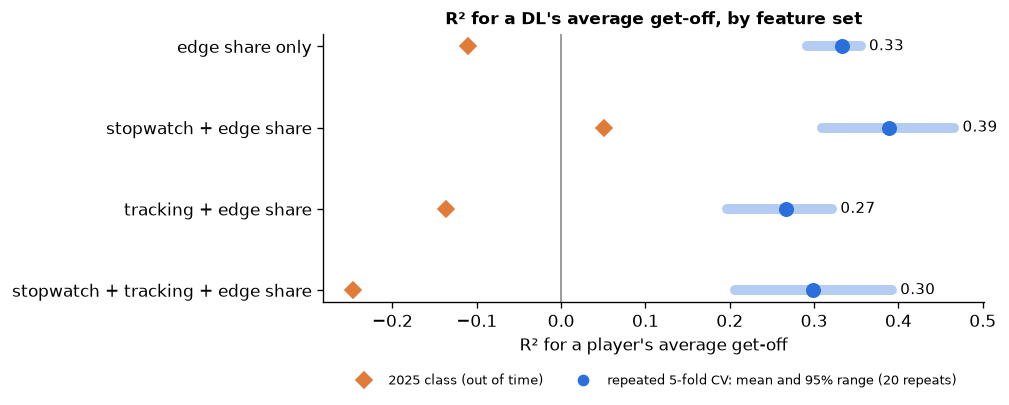

In [9]:
fig, ax = plt.subplots(figsize=(8.5, 3.6))
order = list(SETS.keys())
for i, name in enumerate(order):
    r_ = cv_summary.set_index("feature_set").loc[name]
    ax.plot([r_.p2_5, r_.p97_5], [i, i], color=BLUE, lw=6, alpha=.35, solid_capstyle="round")
    ax.plot(r_["mean"], i, "o", color=BLUE, ms=8)
    ax.text(r_.p97_5 + .01, i, f"{r_['mean']:.2f}", va="center", fontsize=9)
    if len(oot):
        ax.plot(oot.set_index("feature_set").loc[name, "test_r2"], i, "D", color=ORANGE, ms=7,
                label="2025 class (out of time)" if i == 0 else None)
ax.axvline(0, color=GREY, lw=1)
ax.plot([], [], "o", color=BLUE, label=f"repeated 5-fold CV: mean and 95% range ({CV_REPEATS} repeats)")
ax.set_yticks(range(len(order)), order); ax.invert_yaxis(); ax.set_xlabel("R² for a player's average get-off")
ax.legend(frameon=False, fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.22), ncol=2)
ax.set_title("R² for a DL's average get-off, by feature set", fontweight="bold", fontsize=10)
fig.tight_layout(); fig.savefig(C.FIG_DIR / "07b_player_level_r2.png", bbox_inches="tight"); plt.show()

## 6. Reconciling the player view with the snap-level models
Notebook 07 found that adding a trait to the snap-level model raised get-off R² by only about 0.006. The two results agree once you split the variance of get-off into a **between-player** part (who the player is) and a **within-player** part (snap-to-snap). A player-level R² only applies to the between-player part, so its snap-level equivalent is roughly

**snap-level gain ≈ player-level R² × between-player share of variance.**

The variance split is a one-way ANOVA (method-of-moments) estimate, from Spark aggregates over every DL rush snap.

In [10]:
grand = rush.agg(F.avg("player_get_off")).first()[0]
agg = rush.groupBy("nfl_id").agg(F.count(F.lit(1)).alias("n"), F.avg("player_get_off").alias("m"),
                                 F.sum(F.col("player_get_off") ** 2).alias("ss"))
a = agg.agg(F.sum("n").alias("N"), F.count(F.lit(1)).alias("k"), F.sum(F.col("n") ** 2).alias("n2"),
            F.sum(F.col("n") * (F.col("m") - F.lit(grand)) ** 2).alias("ssb"),
            F.sum(F.col("ss") - F.col("n") * F.col("m") ** 2).alias("ssw")).first()
msb, msw = a.ssb / (a.k - 1), a.ssw / (a.N - a.k)
n0 = (a.N - a.n2 / a.N) / (a.k - 1)
var_b = max((msb - msw) / n0, 0)
between_share = var_b / (var_b + msw)
best = cv_summary.set_index("feature_set")
rec = [dict(quantity="between-player share of get-off variance (ICC, all DL rush snaps)", value=between_share)]
for name in ["stopwatch + edge share", "tracking + edge share", "stopwatch + tracking + edge share"]:
    rec.append(dict(quantity=f"implied snap-level gain from player-level R², {name}",
                    value=max(best.loc[name, "mean"] - best.loc["edge share only", "mean"], 0) * between_share))
te = C.TABLE_DIR / "07_trait_effects.csv"
if te.exists():
    t = spark.read.csv(str(te), header=True, inferSchema=True).filter((F.col("task") == "dl_getoff") & F.col("model").isin("burst", "stopwatch", "traits"))
    rec += [dict(quantity=f"measured snap-level gain in notebook 07 ({r.model})", value=r.delta) for r in t.collect()]
recon = pd.DataFrame(rec)
recon.to_csv(C.TABLE_DIR / "07b_reconciliation.csv", index=False)
recon.round(4)

,quantity,value
0,"between-player share of get-off variance (ICC,...",0.0977
1,"implied snap-level gain from player-level R², ...",0.0055
2,"implied snap-level gain from player-level R², ...",0.0000
3,"implied snap-level gain from player-level R², ...",0.0000
4,measured snap-level gain in notebook 07 (burst),0.0072
5,measured snap-level gain in notebook 07 (traits),0.0225
6,measured snap-level gain in notebook 07 (stopw...,0.0201


**Reading it.** Only a small share of the variation in get-off is between players. Most of it comes from the snap itself: the down, the call, the blocker. So even a player-level model that explains a real part of the between-player differences can only add a few thousandths of R² when it is scored snap by snap. That is the size notebook 07 measured. The player view and the snap view tell one story: **within the 2023–25 classes, the stopwatch speed drills help separate faster and slower get-off players beyond alignment alone, but get-off on any one snap is mostly the snap itself.** The out-of-time check has only about a dozen players from the 2025 class, too few to confirm or rule out the player-level gain, so the report should quote the cross-validated range together with that caveat.

In [11]:
summary = pd.concat([corr.assign(section="correlation")[["section", "feature", "n", "pearson_r", "ci_lo", "ci_hi"]],
                     cv_summary.assign(section="repeated CV R²").rename(columns={"feature_set": "feature", "mean": "pearson_r",
                                                                                 "p2_5": "ci_lo", "p97_5": "ci_hi"})], ignore_index=True)
summary.to_csv(C.TABLE_DIR / "07b_player_level_summary.csv", index=False)
spark.stop()